In [1]:
!pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]


In [2]:
import medmnist
from medmnist import PneumoniaMNIST, INFO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader
from torchvision import transforms

import sklearn
from sklearn.preprocessing import StandardScaler

import random
import hashlib

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the 224 x 224 PneumoniaMNIST+ dataset

train_dataset = PneumoniaMNIST(
    split="train",
    size=224,
    download=True
)

val_dataset = PneumoniaMNIST(
    split="val",
    size=224,
    download=True
)

test_dataset = PneumoniaMNIST(
    split="test",
    size=224,
    download=True
)

# Print the number of images in each partition

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

print("Total images:",
      len(train_dataset) +
      len(val_dataset) +
      len(test_dataset))

100%|██████████| 214M/214M [03:08<00:00, 1.14MB/s]


Training images: 4708
Validation images: 524
Testing images: 624
Total images: 5856


In [4]:
# Inspect dataset characteristics

datasets = {
    "Training": train_dataset,
    "Validation": val_dataset,
    "Testing": test_dataset
}

for name, dataset in datasets.items():
    print(f"\n{name} dataset:")
    print("Image array shape:", dataset.imgs.shape)
    print("Label array shape:", dataset.labels.shape)
    print("Image data type:", dataset.imgs.dtype)
    print("Minimum pixel value:", dataset.imgs.min())
    print("Maximum pixel value:", dataset.imgs.max())
    print("Unique labels:", np.unique(dataset.labels))

# Confirm the meaning of each label
print("\nLabel definitions:")
print(INFO["pneumoniamnist"]["label"])


Training dataset:
Image array shape: (4708, 224, 224)
Label array shape: (4708, 1)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Unique labels: [0 1]

Validation dataset:
Image array shape: (524, 224, 224)
Label array shape: (524, 1)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Unique labels: [0 1]

Testing dataset:
Image array shape: (624, 224, 224)
Label array shape: (624, 1)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Unique labels: [0 1]

Label definitions:
{'0': 'normal', '1': 'pneumonia'}


In [5]:
# Calculate class distribution for each dataset partition

class_distribution = []

for name, dataset in datasets.items():

    labels = dataset.labels.flatten()

    normal_count = np.sum(labels == 0)
    pneumonia_count = np.sum(labels == 1)
    total = len(labels)

    class_distribution.append({
        "Partition": name,
        "Normal": normal_count,
        "Pneumonia": pneumonia_count,
        "Total": total,
        "Normal (%)": round(normal_count / total * 100, 2),
        "Pneumonia (%)": round(pneumonia_count / total * 100, 2)
    })

# Convert the results into a table
distribution_df = pd.DataFrame(class_distribution)

display(distribution_df)

,Partition,Normal,Pneumonia,Total,Normal (%),Pneumonia (%)
0,Training,1214,3494,4708,25.79,74.21
1,Validation,135,389,524,25.76,74.24
2,Testing,234,390,624,37.50,62.50


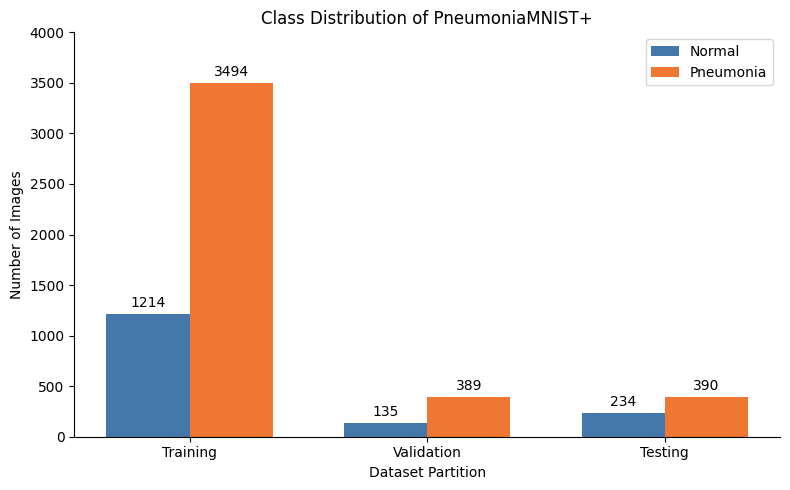

In [6]:
# Visualize class distribution across dataset partitions

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(distribution_df))
width = 0.35

normal_bars = ax.bar(
    x - width / 2,
    distribution_df["Normal"],
    width,
    label="Normal",
    color="#4477AA"
)

pneumonia_bars = ax.bar(
    x + width / 2,
    distribution_df["Pneumonia"],
    width,
    label="Pneumonia",
    color="#EE7733"
)

# Add labels and formatting
ax.set_xlabel("Dataset Partition")
ax.set_ylabel("Number of Images")
ax.set_title("Class Distribution of PneumoniaMNIST+")
ax.set_xticks(x)
ax.set_xticklabels(distribution_df["Partition"])
ax.legend()

# Display the exact number above each bar
ax.bar_label(normal_bars, padding=3)
ax.bar_label(pneumonia_bars, padding=3)

ax.set_ylim(0, 4000)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save high-resolution figures
plt.savefig("class_distribution.png", dpi=300, bbox_inches="tight")
plt.savefig("class_distribution.pdf", bbox_inches="tight")

plt.show()

# Save the numerical results
distribution_df.to_csv("class_distribution.csv", index=False)

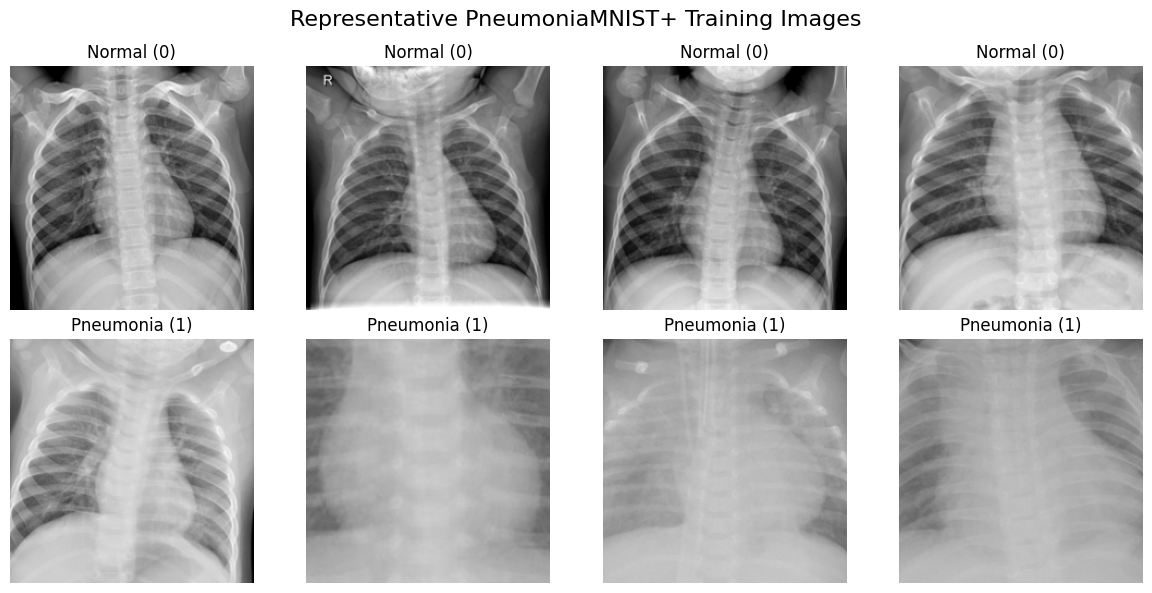

In [7]:
# Visualize representative training images

train_labels = train_dataset.labels.flatten()

# Find the indices of each class
normal_indices = np.where(train_labels == 0)[0]
pneumonia_indices = np.where(train_labels == 1)[0]

# Randomly select four images from each class
rng = np.random.default_rng(42)

normal_samples = rng.choice(
    normal_indices, size=4, replace=False
)

pneumonia_samples = rng.choice(
    pneumonia_indices, size=4, replace=False
)

# Create a figure with two rows and four columns
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):

    # Display normal images
    axes[0, i].imshow(
        train_dataset.imgs[normal_samples[i]],
        cmap="gray", vmin=0, vmax=255
    )
    axes[0, i].set_title("Normal (0)")
    axes[0, i].axis("off")

    # Display pneumonia images
    axes[1, i].imshow(
        train_dataset.imgs[pneumonia_samples[i]],
        cmap="gray", vmin=0, vmax=255
    )
    axes[1, i].set_title("Pneumonia (1)")
    axes[1, i].axis("off")

fig.suptitle(
    "Representative PneumoniaMNIST+ Training Images",
    fontsize=16
)

plt.tight_layout()

# Save figures
plt.savefig("sample_chest_xrays.png",
            dpi=300, bbox_inches="tight")

plt.savefig("sample_chest_xrays.pdf",
            bbox_inches="tight")

plt.show()

In [8]:
# Check dataset quality

quality_results = []

for name, dataset in datasets.items():

    images = dataset.imgs
    labels = dataset.labels.flatten()

    # Check for missing or invalid values
    missing_pixels = np.isnan(images).sum()
    infinite_pixels = np.isinf(images).sum()

    # Check for invalid labels
    invalid_labels = np.sum(~np.isin(labels, [0, 1]))

    # Check for blank or constant images
    min_pixels = images.min(axis=(1, 2))
    max_pixels = images.max(axis=(1, 2))

    black_images = np.sum(max_pixels == 0)
    white_images = np.sum(min_pixels == 255)
    constant_images = np.sum(min_pixels == max_pixels)

    quality_results.append({
        "Partition": name,
        "Missing pixels": missing_pixels,
        "Infinite pixels": infinite_pixels,
        "Invalid labels": invalid_labels,
        "Black images": black_images,
        "White images": white_images,
        "Constant images": constant_images,
        "Image-label match": len(images) == len(labels),
        "Correct dimensions": images.shape[1:] == (224, 224)
    })

# Display quality assessment results
quality_df = pd.DataFrame(quality_results)

display(quality_df)

# Save results for documentation
quality_df.to_csv("data_quality_report.csv", index=False)

,Partition,Missing pixels,Infinite pixels,Invalid labels,Black images,White images,Constant images,Image-label match,Correct dimensions
0,Training,0,0,0,0,0,0,True,True
1,Validation,0,0,0,0,0,0,True,True
2,Testing,0,0,0,0,0,0,True,True


In [9]:
# Check for exact duplicate images using SHA-256 hashing

image_hashes = {}

for name, dataset in datasets.items():

    hashes = [
        hashlib.sha256(image.tobytes()).hexdigest()
        for image in dataset.imgs
    ]

    image_hashes[name] = hashes

    # Count duplicate images within each partition
    duplicate_count = len(hashes) - len(set(hashes))

    print(f"{name} dataset:")
    print(f"  Total images: {len(hashes)}")
    print(f"  Unique images: {len(set(hashes))}")
    print(f"  Duplicate images: {duplicate_count}")
    print()

# Check for identical images across partitions

train_hashes = set(image_hashes["Training"])
val_hashes = set(image_hashes["Validation"])
test_hashes = set(image_hashes["Testing"])

print("Exact image overlap between partitions:")

print("Training vs Validation:",
      len(train_hashes & val_hashes))

print("Training vs Testing:",
      len(train_hashes & test_hashes))

print("Validation vs Testing:",
      len(val_hashes & test_hashes))

Training dataset:
  Total images: 4708
  Unique images: 4690
  Duplicate images: 18

Validation dataset:
  Total images: 524
  Unique images: 524
  Duplicate images: 0

Testing dataset:
  Total images: 624
  Unique images: 621
  Duplicate images: 3

Exact image overlap between partitions:
Training vs Validation: 8
Training vs Testing: 0
Validation vs Testing: 0


In [10]:
# Investigate duplicate images and their labels

from collections import defaultdict

hash_records = defaultdict(list)

for name, dataset in datasets.items():

    labels = dataset.labels.flatten()

    for index, image_hash in enumerate(image_hashes[name]):

        hash_records[image_hash].append({
            "Partition": name,
            "Image index": index,
            "Label": int(labels[index]),
            "Class": "Normal" if labels[index] == 0
                     else "Pneumonia"
        })

duplicate_records = []
group_id = 0

for image_hash, records in hash_records.items():

    if len(records) > 1:

        group_id += 1

        partitions = set(r["Partition"] for r in records)
        labels = set(r["Label"] for r in records)

        for record in records:

            duplicate_records.append({
                "Duplicate group": group_id,
                **record,
                "Cross-partition overlap": len(partitions) > 1,
                "Conflicting labels": len(labels) > 1
            })

duplicate_df = pd.DataFrame(duplicate_records)

display(duplicate_df)

# Summarize duplicate findings
print("Total duplicate groups:", group_id)

print("Groups with conflicting labels:",
      duplicate_df.loc[
          duplicate_df["Conflicting labels"],
          "Duplicate group"
      ].nunique())

print("Groups appearing across partitions:",
      duplicate_df.loc[
          duplicate_df["Cross-partition overlap"],
          "Duplicate group"
      ].nunique())

# Save findings
duplicate_df.to_csv("duplicate_image_report.csv", index=False)

,Duplicate group,Partition,Image index,Label,Class,Cross-partition overlap,Conflicting labels
0,1,Training,29,1,Pneumonia,False,False
1,1,Training,3365,1,Pneumonia,False,False
2,2,Training,97,1,Pneumonia,False,False
3,2,Training,4422,1,Pneumonia,False,False
4,3,Training,226,1,Pneumonia,False,False
5,3,Training,1366,1,Pneumonia,False,False
6,4,Training,289,1,Pneumonia,True,False
7,4,Training,3170,1,Pneumonia,True,False
8,4,Validation,172,1,Pneumonia,True,False
9,5,Training,662,1,Pneumonia,True,False


Total duplicate groups: 27
Groups with conflicting labels: 0
Groups appearing across partitions: 8


In [11]:
# Preview proposed training dataset cleaning
# This does not modify the original dataset

seen_hashes = set()
clean_train_indices = []

removed_duplicates = 0
removed_overlap = 0

for index, image_hash in enumerate(image_hashes["Training"]):

    # Exclude redundant training copies
    if image_hash in seen_hashes:
        removed_duplicates += 1
        continue

    seen_hashes.add(image_hash)

    # Exclude images also appearing in validation
    if image_hash in val_hashes:
        removed_overlap += 1
        continue

    clean_train_indices.append(index)

clean_train_indices = np.array(
    clean_train_indices, dtype=int
)

# Calculate the proposed cleaned class distribution
clean_train_labels = train_dataset.labels[
    clean_train_indices
].flatten()

print("Original training images:", len(train_dataset))
print("Redundant training copies:", removed_duplicates)
print("Training-validation overlap:", removed_overlap)
print("Proposed cleaned training size:", len(clean_train_indices))

print("\nProposed cleaned class distribution:")
print("Normal:", np.sum(clean_train_labels == 0))
print("Pneumonia:", np.sum(clean_train_labels == 1))

# Verify that the proposed training set has no exact overlap
clean_train_hashes = {
    image_hashes["Training"][i]
    for i in clean_train_indices
}

print("\nRemaining training-validation overlap:",
      len(clean_train_hashes & val_hashes))

print("Remaining training-testing overlap:",
      len(clean_train_hashes & test_hashes))

Original training images: 4708
Redundant training copies: 18
Training-validation overlap: 8
Proposed cleaned training size: 4682

Proposed cleaned class distribution:
Normal: 1213
Pneumonia: 3469

Remaining training-validation overlap: 0
Remaining training-testing overlap: 0


In [12]:
# Save the proposed cleaned training indices

np.save("clean_train_indices.npy", clean_train_indices)

# Create a human-readable record of excluded images

excluded_indices = np.setdiff1d(
    np.arange(len(train_dataset)),
    clean_train_indices
)

excluded_df = pd.DataFrame({
    "Image index": excluded_indices,
    "Label": train_dataset.labels[excluded_indices].flatten()
})

excluded_df["Class"] = excluded_df["Label"].map({
    0: "Normal",
    1: "Pneumonia"
})

excluded_df.to_csv(
    "excluded_training_images.csv",
    index=False
)

# Verify the saved indices

saved_indices = np.load("clean_train_indices.npy")

assert np.array_equal(saved_indices, clean_train_indices)
assert len(clean_train_hashes) == len(clean_train_indices)
assert len(clean_train_hashes & val_hashes) == 0
assert len(clean_train_hashes & test_hashes) == 0

print("Cleaned training indices saved successfully.")
print("Retained training images:", len(saved_indices))
print("Excluded training images:", len(excluded_indices))
print("All verification checks passed.")

Cleaned training indices saved successfully.
Retained training images: 4682
Excluded training images: 26
All verification checks passed.


In [13]:
# Select the training subset
# True = proposed cleaned dataset
# False = original official dataset

USE_CLEAN_TRAINING = True

if USE_CLEAN_TRAINING:
    active_train_indices = clean_train_indices
else:
    active_train_indices = np.arange(len(train_dataset))

# Select training images and labels

active_train_images = train_dataset.imgs[active_train_indices]
active_train_labels = train_dataset.labels[
    active_train_indices
].flatten()

# Calculate normalization statistics on the 0-1 scale

train_mean = float(active_train_images.mean() / 255.0)
train_std = float(active_train_images.std() / 255.0)

# Display results

print("Training images used:", len(active_train_images))
print("Training mean:", round(train_mean, 6))
print("Training standard deviation:", round(train_std, 6))

# Verify that the standard deviation is valid

assert train_std > 0

# Save normalization statistics

normalization_df = pd.DataFrame({
    "Cleaned training subset": [USE_CLEAN_TRAINING],
    "Training images": [len(active_train_images)],
    "Mean": [train_mean],
    "Standard deviation": [train_std]
})

normalization_df.to_csv(
    "normalization_statistics.csv",
    index=False
)

Training images used: 4682
Training mean: 0.571573
Training standard deviation: 0.177011


In [14]:
# Calculate balanced class weights using training labels only

from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=active_train_labels
)

# Format for classical machine learning models

class_weight_dict = {
    int(label): float(weight)
    for label, weight in zip(classes, class_weights)
}

# Format for PyTorch deep learning models

class_weight_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
)

# Display results

print("Class weights:")
print("Normal (0):", round(class_weights[0], 6))
print("Pneumonia (1):", round(class_weights[1], 6))

print("\nScikit-learn format:")
print(class_weight_dict)

print("\nPyTorch format:")
print(class_weight_tensor)

# Save class weights

class_weights_df = pd.DataFrame({
    "Label": classes,
    "Class": ["Normal", "Pneumonia"],
    "Training count": [
        np.sum(active_train_labels == 0),
        np.sum(active_train_labels == 1)
    ],
    "Weight": class_weights
})

display(class_weights_df)

class_weights_df.to_csv(
    "class_weights.csv",
    index=False
)

Class weights:
Normal (0): 1.929926
Pneumonia (1): 0.674834

Scikit-learn format:
{0: 1.9299258037922506, 1: 0.6748342461804555}

PyTorch format:
tensor([1.9299, 0.6748])


,Label,Class,Training count,Weight
0,0,Normal,1213,1.929926
1,1,Pneumonia,3469,0.674834


In [15]:
# Define conservative data augmentation for chest X-rays

from PIL import Image
from torchvision.transforms import InterpolationMode

augmentation_transform = transforms.Compose([

    # Small rotations and positioning shifts
    transforms.RandomAffine(
        degrees=5,
        translate=(0.03, 0.03),
        interpolation=InterpolationMode.BILINEAR,
        fill=0
    ),

    # Small brightness and contrast variations
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    )
])

print("Data augmentation pipeline created successfully.")

print(augmentation_transform)

Data augmentation pipeline created successfully.
Compose(
    RandomAffine(degrees=[-5.0, 5.0], translate=(0.03, 0.03), interpolation=bilinear)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
)


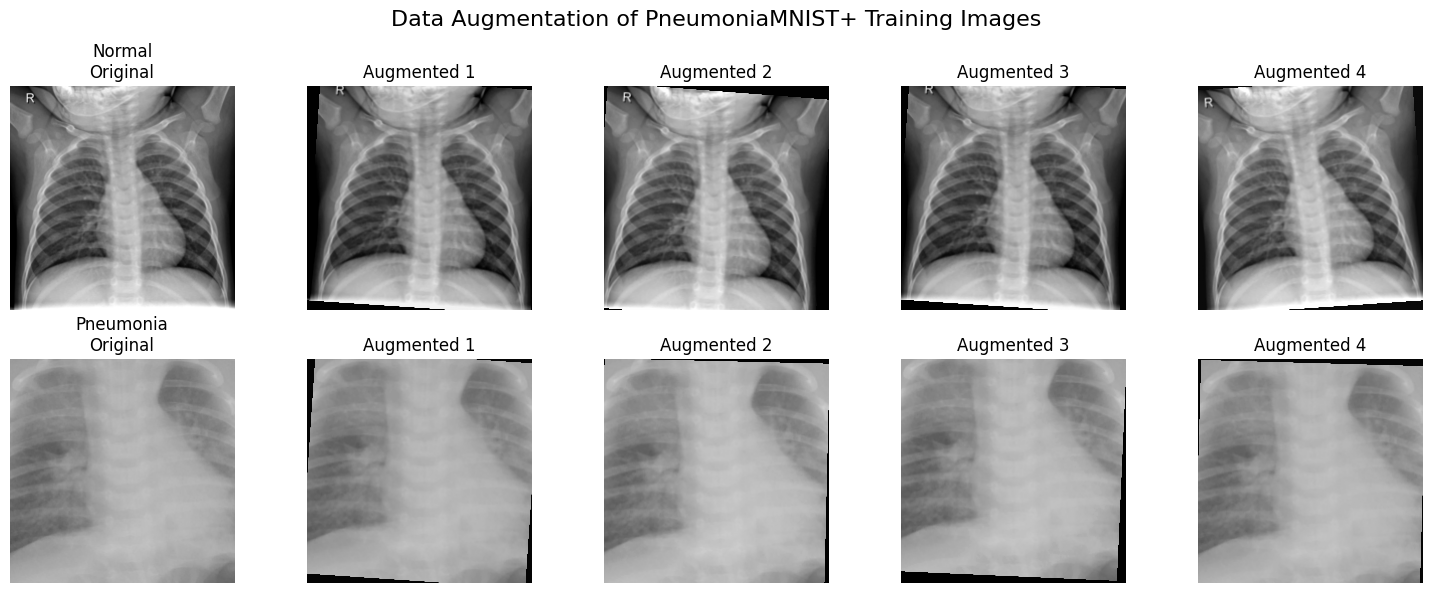

In [16]:
# Visually inspect the effects of data augmentation

rng = np.random.default_rng(42)

# Select one training image from each class
normal_index = rng.choice(
    np.where(active_train_labels == 0)[0]
)

pneumonia_index = rng.choice(
    np.where(active_train_labels == 1)[0]
)

# Convert NumPy arrays into PIL images
normal_image = Image.fromarray(
    active_train_images[normal_index]
)

pneumonia_image = Image.fromarray(
    active_train_images[pneumonia_index]
)

# Set seed for reproducible augmentation examples
torch.manual_seed(42)

# Create figure
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row, (image, class_name) in enumerate([
    (normal_image, "Normal"),
    (pneumonia_image, "Pneumonia")
]):

    # Display original image
    axes[row, 0].imshow(
        image, cmap="gray", vmin=0, vmax=255
    )
    axes[row, 0].set_title(f"{class_name}\nOriginal")
    axes[row, 0].axis("off")

    # Generate four augmented versions
    for col in range(1, 5):

        augmented_image = augmentation_transform(image)

        axes[row, col].imshow(
            augmented_image,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row, col].set_title(f"Augmented {col}")
        axes[row, col].axis("off")

fig.suptitle(
    "Data Augmentation of PneumoniaMNIST+ Training Images",
    fontsize=16
)

plt.tight_layout()

# Save figures for documentation
plt.savefig("augmentation_examples.png",
            dpi=300, bbox_inches="tight")

plt.savefig("augmentation_examples.pdf",
            bbox_inches="tight")

plt.show()

In [17]:
# Step 14A: Prepare majority-class baseline

# Extract labels for all three partitions
y_train = active_train_labels.astype(np.int64)
y_val = val_dataset.labels.flatten().astype(np.int64)
y_test = test_dataset.labels.flatten().astype(np.int64)

# Determine the majority class using training labels only
majority_class = int(np.bincount(y_train).argmax())

class_names = {
    0: "Normal",
    1: "Pneumonia"
}

# Calculate training class prevalence
majority_prevalence = np.mean(
    y_train == majority_class
)

# Generate validation predictions
baseline_val_predictions = np.full(
    len(y_val),
    majority_class,
    dtype=np.int64
)

# Display baseline information
print("Majority class:", majority_class)
print("Predicted class:", class_names[majority_class])
print("Training prevalence:",
      round(majority_prevalence * 100, 2), "%")

print("\nLabel array shapes:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

print("\nUnique baseline validation predictions:")
print(np.unique(baseline_val_predictions))

print("\nMajority-class baseline prepared successfully.")

Majority class: 1
Predicted class: Pneumonia
Training prevalence: 74.09 %

Label array shapes:
Training: (4682,)
Validation: (524,)
Testing: (624,)

Unique baseline validation predictions:
[1]

Majority-class baseline prepared successfully.


In [18]:
# Step 14B.1: Prepare classical machine learning features

CLASSICAL_IMAGE_SIZE = 32

def prepare_classical_features(images):

    features = np.empty(
        (len(images), CLASSICAL_IMAGE_SIZE ** 2),
        dtype=np.float32
    )

    for i, image in enumerate(images):

        # Convert array into a PIL image
        pil_image = Image.fromarray(image)

        # Downsample to 32 x 32 pixels
        resized_image = pil_image.resize(
            (CLASSICAL_IMAGE_SIZE, CLASSICAL_IMAGE_SIZE),
            resample=Image.Resampling.BILINEAR
        )

        # Convert to numerical array and rescale to 0-1
        image_array = np.asarray(
            resized_image,
            dtype=np.float32
        ) / 255.0

        # Flatten into a one-dimensional feature vector
        features[i] = image_array.flatten()

    return features


# Apply identical preprocessing to all partitions

X_train_classical = prepare_classical_features(
    active_train_images
)

X_val_classical = prepare_classical_features(
    val_dataset.imgs
)

X_test_classical = prepare_classical_features(
    test_dataset.imgs
)

# Verify the resulting feature arrays

print("Classical machine learning feature shapes:")
print("Training:", X_train_classical.shape)
print("Validation:", X_val_classical.shape)
print("Testing:", X_test_classical.shape)

print("\nFeatures per image:", X_train_classical.shape[1])
print("Data type:", X_train_classical.dtype)
print("Minimum training value:", X_train_classical.min())
print("Maximum training value:", X_train_classical.max())

# Verify that features and labels correspond in count

assert len(X_train_classical) == len(y_train)
assert len(X_val_classical) == len(y_val)
assert len(X_test_classical) == len(y_test)

print("\nAll verification checks passed.")

Classical machine learning feature shapes:
Training: (4682, 1024)
Validation: (524, 1024)
Testing: (624, 1024)

Features per image: 1024
Data type: float32
Minimum training value: 0.0
Maximum training value: 1.0

All verification checks passed.


In [19]:
# Step 14B.2: Standardize classical machine learning features

from sklearn.preprocessing import StandardScaler
import joblib

# Create the standardization object
classical_scaler = StandardScaler()

# Fit ONLY on training features
X_train_classical_scaled = classical_scaler.fit_transform(
    X_train_classical
)

# Apply the same training-derived statistics
# to validation and testing features

X_val_classical_scaled = classical_scaler.transform(
    X_val_classical
)

X_test_classical_scaled = classical_scaler.transform(
    X_test_classical
)

# Verify feature shapes

print("Standardized feature shapes:")
print("Training:", X_train_classical_scaled.shape)
print("Validation:", X_val_classical_scaled.shape)
print("Testing:", X_test_classical_scaled.shape)

# Check standardization of nonconstant training features

nonconstant_features = classical_scaler.var_ > 0

feature_means = X_train_classical_scaled.mean(axis=0)
feature_stds = X_train_classical_scaled.std(axis=0)

print("\nAverage training feature mean:",
      round(float(feature_means.mean()), 6))

print("Average nonconstant training feature SD:",
      round(float(feature_stds[nonconstant_features].mean()), 6))

# Verify that all values are finite

assert np.isfinite(X_train_classical_scaled).all()
assert np.isfinite(X_val_classical_scaled).all()
assert np.isfinite(X_test_classical_scaled).all()

# Save the fitted scaler for reproducibility

joblib.dump(
    classical_scaler,
    "classical_standard_scaler.joblib"
)

print("\nStandardScaler saved successfully.")
print("All verification checks passed.")

Standardized feature shapes:
Training: (4682, 1024)
Validation: (524, 1024)
Testing: (624, 1024)

Average training feature mean: -0.0
Average nonconstant training feature SD: 1.0

StandardScaler saved successfully.
All verification checks passed.


In [20]:
# Step 14C.1: Define CNN preprocessing transformations

# Training transformations
cnn_train_transform = transforms.Compose([

    # Apply our previously defined augmentation
    augmentation_transform,

    # Convert image to tensor and rescale to 0-1
    transforms.ToTensor(),

    # Normalize using training-derived statistics
    transforms.Normalize(
        mean=[train_mean],
        std=[train_std]
    )
])

# Validation and testing transformations
cnn_eval_transform = transforms.Compose([

    # Convert image to tensor and rescale to 0-1
    transforms.ToTensor(),

    # Apply the same training-derived normalization
    transforms.Normalize(
        mean=[train_mean],
        std=[train_std]
    )
])

print("CNN training transformations:")
print(cnn_train_transform)

print("\nCNN validation/testing transformations:")
print(cnn_eval_transform)

print("\nCNN preprocessing pipelines created successfully.")

CNN training transformations:
Compose(
    Compose(
    RandomAffine(degrees=[-5.0, 5.0], translate=(0.03, 0.03), interpolation=bilinear)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
)
    ToTensor()
    Normalize(mean=[0.571572608495956], std=[0.17701138110066306])
)

CNN validation/testing transformations:
Compose(
    ToTensor()
    Normalize(mean=[0.571572608495956], std=[0.17701138110066306])
)

CNN preprocessing pipelines created successfully.


In [21]:
# Step 14C.2: Verify CNN preprocessing transformations

from PIL import Image

# Select one training image
sample_image = Image.fromarray(active_train_images[0])

# Apply both preprocessing pipelines to the same image
cnn_train_sample = cnn_train_transform(sample_image)
cnn_eval_sample = cnn_eval_transform(sample_image)

# Inspect the transformed training image
print("CNN training sample:")
print("Shape:", cnn_train_sample.shape)
print("Data type:", cnn_train_sample.dtype)
print("Minimum value:", cnn_train_sample.min().item())
print("Maximum value:", cnn_train_sample.max().item())

# Inspect the transformed evaluation image
print("\nCNN evaluation sample:")
print("Shape:", cnn_eval_sample.shape)
print("Data type:", cnn_eval_sample.dtype)
print("Minimum value:", cnn_eval_sample.min().item())
print("Maximum value:", cnn_eval_sample.max().item())

# Verify the expected dimensions and data type
assert cnn_train_sample.shape == (1, 224, 224)
assert cnn_eval_sample.shape == (1, 224, 224)

assert cnn_train_sample.dtype == torch.float32
assert cnn_eval_sample.dtype == torch.float32

# Verify that all pixel values are finite
assert torch.isfinite(cnn_train_sample).all()
assert torch.isfinite(cnn_eval_sample).all()

print("\nAll CNN preprocessing verification checks passed.")

CNN training sample:
Shape: torch.Size([1, 224, 224])
Data type: torch.float32
Minimum value: -3.229016065597534
Maximum value: 2.4203381538391113

CNN evaluation sample:
Shape: torch.Size([1, 224, 224])
Data type: torch.float32
Minimum value: -3.229016065597534
Maximum value: 2.110177516937256

All CNN preprocessing verification checks passed.


In [22]:
# Step 14C.3: Create PyTorch datasets for the CNN

from torch.utils.data import Dataset
from PIL import Image

# Define a reusable dataset class
class ChestXrayDataset(Dataset):

    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = np.asarray(labels).reshape(-1)
        self.transform = transform

        assert len(self.images) == len(self.labels)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image = Image.fromarray(self.images[idx])
        label = int(self.labels[idx])

        if self.transform is not None:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


# Create the CNN training dataset
cnn_train_dataset = ChestXrayDataset(
    active_train_images,
    y_train,
    transform=cnn_train_transform
)

# Create the CNN validation dataset
cnn_val_dataset = ChestXrayDataset(
    val_dataset.imgs,
    y_val,
    transform=cnn_eval_transform
)

# Create the CNN testing dataset
cnn_test_dataset = ChestXrayDataset(
    test_dataset.imgs,
    y_test,
    transform=cnn_eval_transform
)

# Verify dataset sizes
print("CNN training dataset:", len(cnn_train_dataset))
print("CNN validation dataset:", len(cnn_val_dataset))
print("CNN testing dataset:", len(cnn_test_dataset))

# Verify an individual training sample
image, label = cnn_train_dataset[0]

print("\nSample image shape:", image.shape)
print("Sample image data type:", image.dtype)
print("Sample label:", label.item())
print("Sample label data type:", label.dtype)

assert image.shape == (1, 224, 224)
assert label.item() in [0, 1]

print("\nCNN datasets created successfully.")

CNN training dataset: 4682
CNN validation dataset: 524
CNN testing dataset: 624

Sample image shape: torch.Size([1, 224, 224])
Sample image data type: torch.float32
Sample label: 1
Sample label data type: torch.int64

CNN datasets created successfully.


In [23]:
# Step 14C.4: Create CNN DataLoaders

from torch.utils.data import DataLoader

BATCH_SIZE = 32
SEED = 42

# Set a reproducible random seed
torch.manual_seed(SEED)

generator = torch.Generator()
generator.manual_seed(SEED)

# Training DataLoader
cnn_train_loader = DataLoader(
    cnn_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    drop_last=False,
    generator=generator
)

# Validation DataLoader
cnn_val_loader = DataLoader(
    cnn_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

# Testing DataLoader
cnn_test_loader = DataLoader(
    cnn_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

# Verify the number of batches
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(cnn_train_loader))
print("Validation batches:", len(cnn_val_loader))
print("Testing batches:", len(cnn_test_loader))

print("\nCNN DataLoaders created successfully.")

Batch size: 32
Training batches: 147
Validation batches: 17
Testing batches: 20

CNN DataLoaders created successfully.


In [24]:
# Step 14C.5: Verify CNN DataLoaders

# Retrieve one batch from training and validation
train_images_batch, train_labels_batch = next(
    iter(cnn_train_loader)
)

val_images_batch, val_labels_batch = next(
    iter(cnn_val_loader)
)

# Inspect each batch
for name, images, labels in [
    ("Training", train_images_batch, train_labels_batch),
    ("Validation", val_images_batch, val_labels_batch)
]:
    print(f"\n{name} batch:")
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)
    print("Unique labels:", torch.unique(labels))

    # Verify image and label dimensions
    assert images.shape == (BATCH_SIZE, 1, 224, 224)
    assert labels.shape == (BATCH_SIZE,)

    # Verify data types
    assert images.dtype == torch.float32
    assert labels.dtype == torch.long

    # Verify numerical validity
    assert torch.isfinite(images).all()
    assert ((labels == 0) | (labels == 1)).all()

# Verify validation label order
assert np.array_equal(
    val_labels_batch.numpy(),
    y_val[:BATCH_SIZE]
)

print("\nAll CNN DataLoader verification checks passed.")


Training batch:
Image shape: torch.Size([32, 1, 224, 224])
Label shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Unique labels: tensor([0, 1])

Validation batch:
Image shape: torch.Size([32, 1, 224, 224])
Label shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Unique labels: tensor([0, 1])

All CNN DataLoader verification checks passed.


In [25]:
# Step 14D.1: Define transfer learning preprocessing

# Standard ImageNet normalization statistics
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training transformations
transfer_train_transform = transforms.Compose([
    augmentation_transform,
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# Validation and testing transformations
transfer_eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Transfer learning training transformations:")
print(transfer_train_transform)

print("\nTransfer learning validation/testing transformations:")
print(transfer_eval_transform)

print("\nTransfer learning preprocessing pipelines created successfully.")

Transfer learning training transformations:
Compose(
    Compose(
    RandomAffine(degrees=[-5.0, 5.0], translate=(0.03, 0.03), interpolation=bilinear)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
)
    Grayscale(num_output_channels=3)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Transfer learning validation/testing transformations:
Compose(
    Grayscale(num_output_channels=3)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Transfer learning preprocessing pipelines created successfully.


In [26]:
# Step 14D.2: Verify transfer learning transformations

from PIL import Image

# Select an image from the active training dataset
sample_image = Image.fromarray(active_train_images[0])

# Apply training and evaluation transformations
transfer_train_sample = transfer_train_transform(sample_image)
transfer_eval_sample = transfer_eval_transform(sample_image)

# Inspect training sample
print("Transfer learning training sample:")
print("Shape:", transfer_train_sample.shape)
print("Data type:", transfer_train_sample.dtype)
print("Minimum value:", transfer_train_sample.min().item())
print("Maximum value:", transfer_train_sample.max().item())

# Inspect evaluation sample
print("\nTransfer learning evaluation sample:")
print("Shape:", transfer_eval_sample.shape)
print("Data type:", transfer_eval_sample.dtype)
print("Minimum value:", transfer_eval_sample.min().item())
print("Maximum value:", transfer_eval_sample.max().item())

# Verify expected dimensions
assert transfer_train_sample.shape == (3, 224, 224)
assert transfer_eval_sample.shape == (3, 224, 224)

# Verify data types
assert transfer_train_sample.dtype == torch.float32
assert transfer_eval_sample.dtype == torch.float32

# Verify that all pixel values are finite
assert torch.isfinite(transfer_train_sample).all()
assert torch.isfinite(transfer_eval_sample).all()

# Verify that evaluation transformations are deterministic
assert torch.equal(
    transfer_eval_sample,
    transfer_eval_transform(sample_image)
)

print("\nAll transfer learning preprocessing verification checks passed.")

Transfer learning training sample:
Shape: torch.Size([3, 224, 224])
Data type: torch.float32
Minimum value: -2.1179039478302
Maximum value: 2.640000104904175

Transfer learning evaluation sample:
Shape: torch.Size([3, 224, 224])
Data type: torch.float32
Minimum value: -2.1179039478302
Maximum value: 2.395991325378418

All transfer learning preprocessing verification checks passed.


In [29]:
# Step 14D.3: Create transfer learning datasets

transfer_train_dataset = ChestXrayDataset(
    active_train_images,
    y_train,
    transfer_train_transform
)

transfer_val_dataset = ChestXrayDataset(
    val_dataset.imgs,
    y_val,
    transfer_eval_transform
)

transfer_test_dataset = ChestXrayDataset(
    test_dataset.imgs,
    y_test,
    transfer_eval_transform
)

# Verify dataset sizes
print("Transfer learning training dataset:",
      len(transfer_train_dataset))

print("Transfer learning validation dataset:",
      len(transfer_val_dataset))

print("Transfer learning testing dataset:",
      len(transfer_test_dataset))

# Verify an individual training sample
image, label = transfer_train_dataset[0]

print("\nSample image shape:", image.shape)
print("Sample image data type:", image.dtype)
print("Sample label:", label.item())
print("Sample label data type:", label.dtype)

# Verification checks
assert len(transfer_train_dataset) == 4682
assert len(transfer_val_dataset) == 524
assert len(transfer_test_dataset) == 624

assert image.shape == (3, 224, 224)
assert image.dtype == torch.float32
assert label.dtype == torch.int64
assert label.item() in [0, 1]

print("\nTransfer learning datasets created successfully.")

Transfer learning training dataset: 4682
Transfer learning validation dataset: 524
Transfer learning testing dataset: 624

Sample image shape: torch.Size([3, 224, 224])
Sample image data type: torch.float32
Sample label: 1
Sample label data type: torch.int64

Transfer learning datasets created successfully.


In [28]:
# Identify existing image variables
%whos

Variable                     Type                Data/Info
----------------------------------------------------------
BATCH_SIZE                   int                 32
CLASSICAL_IMAGE_SIZE         int                 32
ChestXrayDataset             type                <class '__main__.ChestXrayDataset'>
DataLoader                   type                <class 'torch.utils.data.dataloader.DataLoader'>
Dataset                      type                <class 'torch.utils.data.dataset.Dataset'>
DatasetClass                 type                <class '__main__.ChestXrayDataset'>
IMAGENET_MEAN                list                n=3
IMAGENET_STD                 list                n=3
INFO                         dict                n=18
Image                        module              <module 'PIL.Image' from <...>t-packages/PIL/Image.py'>
InterpolationMode            EnumType            <enum 'InterpolationMode'>
PneumoniaMNIST               type                <class 'medmnist.dataset.Pne

In [30]:
# Step 14D.4: Create transfer learning DataLoaders

from torch.utils.data import DataLoader

transfer_train_loader = DataLoader(
    transfer_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    drop_last=False
)

transfer_val_loader = DataLoader(
    transfer_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

transfer_test_loader = DataLoader(
    transfer_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

# Verify the number of batches
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(transfer_train_loader))
print("Validation batches:", len(transfer_val_loader))
print("Testing batches:", len(transfer_test_loader))

print("\nTransfer learning DataLoaders created successfully.")

Batch size: 32
Training batches: 147
Validation batches: 17
Testing batches: 20

Transfer learning DataLoaders created successfully.


In [31]:
# Step 14D.5: Verify transfer learning DataLoaders

# Retrieve one training batch
transfer_train_images_batch, transfer_train_labels_batch = next(
    iter(transfer_train_loader)
)

# Retrieve one validation batch
transfer_val_images_batch, transfer_val_labels_batch = next(
    iter(transfer_val_loader)
)

# Inspect and verify both batches
for name, images, labels in [
    ("Training", transfer_train_images_batch,
     transfer_train_labels_batch),
    ("Validation", transfer_val_images_batch,
     transfer_val_labels_batch)
]:
    print(f"\n{name} batch:")
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)
    print("Unique labels:", torch.unique(labels))

    # Verification checks
    assert images.shape == (BATCH_SIZE, 3, 224, 224)
    assert labels.shape == (BATCH_SIZE,)
    assert images.dtype == torch.float32
    assert labels.dtype == torch.int64
    assert torch.isfinite(images).all()
    assert ((labels == 0) | (labels == 1)).all()

# Verify validation label order
assert np.array_equal(
    transfer_val_labels_batch.numpy(),
    y_val[:BATCH_SIZE]
)

print("\nAll transfer learning DataLoader verification checks passed.")


Training batch:
Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Unique labels: tensor([0, 1])

Validation batch:
Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Unique labels: tensor([0, 1])

All transfer learning DataLoader verification checks passed.


In [32]:
# Step 15: Final dataset consistency checks

expected_counts = {
    "Training": 4682,
    "Validation": 524,
    "Testing": 624
}

# Compare dataset sizes across preprocessing pipelines
consistency_df = pd.DataFrame({
    "Partition": ["Training", "Validation", "Testing"],

    "Expected": list(expected_counts.values()),

    "Baseline": [
        len(y_train),
        len(y_val),
        len(y_test)
    ],

    "Classical ML": [
        len(X_train_classical_scaled),
        len(X_val_classical_scaled),
        len(X_test_classical_scaled)
    ],

    "CNN": [
        len(cnn_train_dataset),
        len(cnn_val_dataset),
        len(cnn_test_dataset)
    ],

    "Transfer learning": [
        len(transfer_train_dataset),
        len(transfer_val_dataset),
        len(transfer_test_dataset)
    ]
})

display(consistency_df)

# Verify consistency across all pipelines
for column in consistency_df.columns[2:]:
    assert np.array_equal(
        consistency_df[column].values,
        consistency_df["Expected"].values
    )

# Save consistency summary
consistency_df.to_csv(
    "preprocessing_consistency.csv",
    index=False
)

print("\nAll preprocessing dataset counts are consistent.")

,Partition,Expected,Baseline,Classical ML,CNN,Transfer learning
0,Training,4682,4682,4682,4682,4682
1,Validation,524,524,524,524,524
2,Testing,624,624,624,624,624



All preprocessing dataset counts are consistent.


In [33]:
# Step 16: Verify label alignment across datasets

# Establish reference labels from the original datasets
reference_train = train_dataset.labels.reshape(-1)[clean_train_indices]
reference_val = val_dataset.labels.reshape(-1)
reference_test = test_dataset.labels.reshape(-1)

# Verify baseline and classical ML labels
assert np.array_equal(y_train, reference_train)
assert np.array_equal(y_val, reference_val)
assert np.array_equal(y_test, reference_test)

print("Baseline and classical ML label checks passed.")

# Verify CNN and transfer learning dataset labels
datasets_to_check = [
    ("CNN training", cnn_train_dataset, y_train),
    ("CNN validation", cnn_val_dataset, y_val),
    ("CNN testing", cnn_test_dataset, y_test),
    ("Transfer training", transfer_train_dataset, y_train),
    ("Transfer validation", transfer_val_dataset, y_val),
    ("Transfer testing", transfer_test_dataset, y_test)
]

for name, dataset, expected_labels in datasets_to_check:

    actual_labels = np.asarray(dataset.labels).reshape(-1)

    assert np.array_equal(actual_labels, expected_labels), \
        f"Label mismatch in {name}"

    print(f"{name}: label alignment verified.")

print("\nAll label alignment checks passed.")

Baseline and classical ML label checks passed.
CNN training: label alignment verified.
CNN validation: label alignment verified.
CNN testing: label alignment verified.
Transfer training: label alignment verified.
Transfer validation: label alignment verified.
Transfer testing: label alignment verified.

All label alignment checks passed.


In [34]:
# Step 17: Reproducibility and random seeds

import random
import numpy as np
import torch
import json

# Three proposed seeds for repeated experiments
RANDOM_SEEDS = [42, 123, 2026]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Verify reproducibility
set_seed(RANDOM_SEEDS[0])

numpy_sample_1 = np.random.rand(5)
torch_sample_1 = torch.rand(5)

set_seed(RANDOM_SEEDS[0])

numpy_sample_2 = np.random.rand(5)
torch_sample_2 = torch.rand(5)

assert np.array_equal(numpy_sample_1, numpy_sample_2)
assert torch.equal(torch_sample_1, torch_sample_2)

# Save reproducibility configuration
reproducibility_config = {
    "random_seeds": RANDOM_SEEDS,
    "default_seed": RANDOM_SEEDS[0],
    "batch_size": BATCH_SIZE,
    "cudnn_deterministic": True,
    "cudnn_benchmark": False
}

with open("reproducibility_config.json", "w") as f:
    json.dump(reproducibility_config, f, indent=4)

# Reset to default seed
set_seed(RANDOM_SEEDS[0])

print("Random seeds:", RANDOM_SEEDS)
print("Default seed:", RANDOM_SEEDS[0])
print("NumPy reproducibility check passed.")
print("PyTorch reproducibility check passed.")
print("Reproducibility configuration saved successfully.")

Random seeds: [42, 123, 2026]
Default seed: 42
NumPy reproducibility check passed.
PyTorch reproducibility check passed.
Reproducibility configuration saved successfully.


In [35]:
# Step 18: Create performance logging templates

model_names = [
    "Majority-class baseline",
    "Logistic regression",
    "Support vector machine",
    "CNN from scratch",
    "ResNet-18",
    "DenseNet-121"
]

# Create one row per planned model run
experiment_rows = []

for model in model_names:

    # The majority baseline is deterministic
    seeds = [None] if model == "Majority-class baseline" else RANDOM_SEEDS

    for seed in seeds:
        experiment_rows.append({
            "Model": model,
            "Random seed": seed
        })

# Training log template
training_log = pd.DataFrame(experiment_rows)

training_columns = [
    "Hyperparameters",
    "Class weighting",
    "Learning rate",
    "Batch size",
    "Epochs completed",
    "Best epoch",
    "Training time (seconds)",
    "Validation AUROC",
    "Validation AUPRC",
    "Checkpoint path",
    "Notes"
]

for column in training_columns:
    training_log[column] = ""

training_log.to_csv(
    "training_log_template.csv",
    index=False
)

# Evaluation log template
evaluation_log = pd.DataFrame(experiment_rows)

evaluation_columns = [
    "Decision threshold",
    "Threshold selection method",
    "Validation specificity",
    "Specificity target met",
    "Test AUROC",
    "Test AUPRC",
    "Test accuracy",
    "Test balanced accuracy",
    "Test sensitivity",
    "Test specificity",
    "Test precision",
    "Test F1 score",
    "True positives",
    "True negatives",
    "False positives",
    "False negatives",
    "AUROC CI lower",
    "AUROC CI upper",
    "AUPRC CI lower",
    "AUPRC CI upper",
    "Notes"
]

for column in evaluation_columns:
    evaluation_log[column] = ""

evaluation_log.to_csv(
    "evaluation_log_template.csv",
    index=False
)

print("Training log template created successfully.")
print("Evaluation log template created successfully.")
print("Total planned experiment runs:", len(training_log))

display(training_log[["Model", "Random seed"]])

Training log template created successfully.
Evaluation log template created successfully.
Total planned experiment runs: 16


,Model,Random seed
0,Majority-class baseline,NaN
1,Logistic regression,42.0
2,Logistic regression,123.0
3,Logistic regression,2026.0
4,Support vector machine,42.0
5,Support vector machine,123.0
6,Support vector machine,2026.0
7,CNN from scratch,42.0
8,CNN from scratch,123.0
9,CNN from scratch,2026.0


In [36]:
# Step 19: Identify generated preprocessing files

from pathlib import Path

file_extensions = {
    ".csv", ".json", ".npy", ".joblib",
    ".png", ".jpg", ".pdf", ".svg"
}

generated_files = sorted([
    file for file in Path("/content").iterdir()
    if file.is_file() and file.suffix.lower() in file_extensions
])

file_summary = pd.DataFrame([
    {
        "Filename": file.name,
        "Size (KB)": round(file.stat().st_size / 1024, 2)
    }
    for file in generated_files
])

display(file_summary)

print("\nTotal files identified:", len(generated_files))

,Filename,Size (KB)
0,augmentation_examples.pdf,342.37
1,augmentation_examples.png,591.71
2,class_distribution.csv,0.16
3,class_distribution.pdf,13.91
4,class_distribution.png,112.80
5,class_weights.csv,0.10
6,classical_standard_scaler.joblib,24.60
7,clean_train_indices.npy,36.70
8,data_quality_report.csv,0.22
9,duplicate_image_report.csv,2.28



Total files identified: 18


In [37]:
# Step 20: Organize and export preprocessing files

from pathlib import Path
import shutil
from google.colab import files

output_folder = Path("/content/PneumoniaMNIST_Preprocessing")

file_groups = {
    "figures": [
        "augmentation_examples.pdf",
        "augmentation_examples.png",
        "class_distribution.pdf",
        "class_distribution.png",
        "sample_chest_xrays.pdf",
        "sample_chest_xrays.png"
    ],

    "data_reports": [
        "class_distribution.csv",
        "data_quality_report.csv",
        "duplicate_image_report.csv",
        "excluded_training_images.csv",
        "preprocessing_consistency.csv"
    ],

    "preprocessing": [
        "class_weights.csv",
        "classical_standard_scaler.joblib",
        "clean_train_indices.npy",
        "normalization_statistics.csv",
        "reproducibility_config.json"
    ],

    "templates": [
        "training_log_template.csv",
        "evaluation_log_template.csv"
    ]
}

# Create folders and copy files
for folder_name, filenames in file_groups.items():

    destination = output_folder / folder_name
    destination.mkdir(parents=True, exist_ok=True)

    for filename in filenames:
        source = Path("/content") / filename

        assert source.exists(), f"Missing file: {filename}"

        shutil.copy2(source, destination / filename)

    print(f"{folder_name}: {len(filenames)} files copied.")

# Verify the total number of files
total_files = sum(
    1 for file in output_folder.rglob("*")
    if file.is_file()
)

assert total_files == 18

print("\nTotal organized files:", total_files)

# Create ZIP archive
zip_path = shutil.make_archive(
    "/content/PneumoniaMNIST_Preprocessing",
    "zip",
    root_dir="/content",
    base_dir="PneumoniaMNIST_Preprocessing"
)

print("ZIP archive created successfully.")

# Download ZIP archive
files.download(zip_path)

figures: 6 files copied.
data_reports: 5 files copied.
preprocessing: 5 files copied.
templates: 2 files copied.

Total organized files: 18
ZIP archive created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 21. Preprocessing Methodology Summary

### Dataset and data cleaning
The PneumoniaMNIST+ dataset contains 5,856 grayscale chest X-ray images at a resolution of 224 × 224 pixels. The original training, validation and testing partitions contained 4,708, 524 and 624 images, respectively.

Following exact-image duplicate and overlap detection, 26 images were excluded from the training partition: 18 redundant training images and 8 images overlapping with evaluation partitions. The validation and testing partitions remained unchanged.

The final dataset contains:
- Training: 4,682 images
- Validation: 524 images
- Testing: 624 images
- Total: 5,830 images

### Model-specific preprocessing

**Majority-class baseline**
- Majority class determined using the cleaned training labels.
- All predictions assigned to the pneumonia class (label 1).
- Training pneumonia prevalence: 74.09%.

**Logistic regression and support vector machine**
- Images downsampled to 32 × 32 pixels.
- Images flattened into 1,024 intensity features.
- Pixel intensities rescaled to [0, 1].
- StandardScaler fitted exclusively on training features and applied to validation and testing features.

**CNN from scratch**
- Original 224 × 224 resolution retained.
- Single-channel grayscale tensors.
- Normalization using cleaned training-set statistics.
- Training mean: 0.571573.
- Training standard deviation: 0.177011.

**ResNet-18 and DenseNet-121**
- Original 224 × 224 resolution retained.
- Grayscale images converted into three-channel representations.
- Fixed ImageNet normalization statistics used for compatibility with pretrained weights.

### Data augmentation

Augmentation was applied exclusively to the training images for deep learning models:
- Random rotations of up to ±5 degrees.
- Horizontal and vertical translations of up to 3%.
- Brightness adjustments of up to ±10%.
- Contrast adjustments of up to ±10%.

Validation and testing transformations remained deterministic.

### Class imbalance

Class weights were calculated using the cleaned training labels and made available for model training. Validation and testing class distributions were preserved.

### Reproducibility

- Random seeds: 42, 123 and 2026.
- Default batch size: 32.
- Training DataLoaders shuffled.
- Validation and testing DataLoaders maintained their original order.
- Cleaned training indices, normalization statistics and fitted classical feature scaler saved.
- Dataset counts, tensor dimensions, data types and label alignment verified across preprocessing pipelines.

### Limitations

Exact-image duplicate detection does not guarantee patient-level independence or identify all near-duplicate images. The training-set exclusions represent a modification of the original MedMNIST benchmark protocol and must be reported when comparing results with published studies.

In [38]:
# Step 22: Record software dependencies

import sys
from importlib.metadata import version

packages = [
    "medmnist",
    "numpy",
    "pandas",
    "matplotlib",
    "Pillow",
    "scikit-learn",
    "torch",
    "torchvision",
    "joblib"
]

# Record installed package versions
requirements = [
    f"{package}=={version(package)}"
    for package in packages
]

# Save requirements file
with open("requirements.txt", "w") as f:
    f.write("\n".join(requirements) + "\n")

# Display environment information
print("Python version:", sys.version)

print("\nSoftware dependencies:")
for requirement in requirements:
    print(requirement)

print("\nrequirements.txt saved successfully.")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

Software dependencies:
medmnist==3.0.2
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
Pillow==11.3.0
scikit-learn==1.6.1
torch==2.14.1+cpu
torchvision==0.29.1+cpu
joblib==1.6.0

requirements.txt saved successfully.


In [39]:
# Step 23: Document the software environment

import platform

environment_info = {
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "preprocessing_device": "CPU",
    "recommended_deep_learning_device": "GPU",
    "note": (
        "The recorded dependencies describe the preprocessing "
        "environment. GPU-compatible PyTorch and Torchvision "
        "versions should be used for deep learning training."
    )
}

with open("environment_info.json", "w") as f:
    json.dump(environment_info, f, indent=4)

print(json.dumps(environment_info, indent=4))
print("\nEnvironment documentation saved successfully.")

{
    "python_version": "3.13.18",
    "pytorch_version": "2.14.1+cpu",
    "cuda_available": false,
    "preprocessing_device": "CPU",
    "recommended_deep_learning_device": "GPU",
    "note": "The recorded dependencies describe the preprocessing environment. GPU-compatible PyTorch and Torchvision versions should be used for deep learning training."
}

Environment documentation saved successfully.


In [40]:
# Step 24: Finalize the preprocessing package

from pathlib import Path
import shutil
from google.colab import files

output_folder = Path("/content/PneumoniaMNIST_Preprocessing")

# Add software environment files
shutil.copy2("requirements.txt", output_folder)
shutil.copy2("environment_info.json", output_folder)

# Verify the final number of files
total_files = sum(
    1 for file in output_folder.rglob("*")
    if file.is_file()
)

print("Total files in final package:", total_files)

assert total_files == 20

# Create final ZIP archive
final_zip_path = shutil.make_archive(
    "/content/PneumoniaMNIST_Preprocessing_FINAL",
    "zip",
    root_dir="/content",
    base_dir="PneumoniaMNIST_Preprocessing"
)

print("Final preprocessing package created successfully.")

# Download final ZIP
files.download(final_zip_path)

Total files in final package: 20
Final preprocessing package created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>